In [1]:
# Dependencies are already installed in the local Python environment.
import sys
print('Python:', sys.version.split()[0])

Python: 3.11.15


In [2]:
# Local setup: use the existing assignment folder and CIFAR-10 dataset.
from pathlib import Path
notebook_folder = Path.cwd()
if not (notebook_folder / 'cs682').is_dir():
    notebook_folder = notebook_folder / 'assignment2'
assert (notebook_folder / 'cs682').is_dir(), 'Run from the repository or assignment2 folder.'
%cd {notebook_folder}


/Users/while/Desktop/cs/682/assignment2


In [3]:
# These fully connected networks use NumPy layers; no extension build is needed.
print('Using the existing local NumPy layer implementations.')

Using the existing local NumPy layer implementations.


# Batch Normalization
One way to make deep networks easier to train is to use more sophisticated optimization procedures such as SGD+momentum, RMSProp, or Adam. Another strategy is to change the architecture of the network to make it easier to train. 
One idea along these lines is batch normalization which was proposed by [3] in 2015.

The idea is relatively straightforward. Machine learning methods tend to work better when their input data consists of uncorrelated features with zero mean and unit variance. When training a neural network, we can preprocess the data before feeding it to the network to explicitly decorrelate its features; this will ensure that the first layer of the network sees data that follows a nice distribution. However, even if we preprocess the input data, the activations at deeper layers of the network will likely no longer be decorrelated and will no longer have zero mean or unit variance since they are output from earlier layers in the network. Even worse, during the training process the distribution of features at each layer of the network will shift as the weights of each layer are updated.

The authors of [1] hypothesize that the shifting distribution of features inside deep neural networks may make training deep networks more difficult. To overcome this problem, [3] proposes to insert batch normalization layers into the network. At training time, a batch normalization layer uses a minibatch of data to estimate the mean and standard deviation of each feature. These estimated means and standard deviations are then used to center and normalize the features of the minibatch. A running average of these means and standard deviations is kept during training, and at test time these running averages are used to center and normalize features.

It is possible that this normalization strategy could reduce the representational power of the network, since it may sometimes be optimal for certain layers to have features that are not zero-mean or unit variance. To this end, the batch normalization layer includes learnable shift and scale parameters for each feature dimension.

[1] [Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift", ICML 2015.](https://arxiv.org/abs/1502.03167)

In [4]:
# As usual, a bit of setup
import time
import numpy as np
import matplotlib.pyplot as plt
from cs682.classifiers.fc_net import *
from cs682.data_utils import get_CIFAR10_data
from cs682.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs682.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def print_mean_std(x,axis=0):
    print('  means: ', x.mean(axis=axis))
    print('  stds:  ', x.std(axis=axis))
    print() 
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.2})

In [5]:
# Load the (preprocessed) CIFAR10 data.
data = get_CIFAR10_data()
for k, v in data.items():
  print('%s: ' % k, v.shape)

/Users/while/Desktop/cs/682/assignment2/cs682/data_utils.py:15: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return  pickle.load(f, encoding='latin1')


X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


## Batch Normalization: Forward
In the file `cs682/layers.py`, implement the batch normalization forward pass in the function `batchnorm_forward`. Once you have done so, run the following to test your implementation.

Referencing the paper linked to above would be helpful!

In [6]:
# Check the training-time forward pass by checking means and variances
# of features both before and after batch normalization   

# Simulate the forward pass for a two-layer network
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print_mean_std(a,axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))
# Means should be close to zero and stds close to one
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
# Now means should be close to beta and stds close to gamma
print('After batch normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:   [27.18502186 34.21455511 37.68611762]

After batch normalization (gamma=1, beta=0)
  means:  [1.99840144e-17 2.05391260e-17 5.41927614e-17]
  stds:   [0.99999999 1.         1.        ]

After batch normalization (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  means:  [11. 12. 13.]
  stds:   [0.99999999 1.99999999 2.99999999]



In [7]:
# Check the test-time forward pass by running the training-time
# forward pass many times to warm up the running averages, and then
# checking the means and variances of activations after a test-time
# forward pass.

np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Means should be close to zero and stds close to one, but will be
# noisier than training-time forward passes.
print('After batch normalization (test-time):')
print_mean_std(a_norm,axis=0)

After batch normalization (test-time):
  means:  [-0.03927354 -0.04349152 -0.10452688]
  stds:   [1.01531428 1.01238373 0.97819988]



# Batch normalization: Backward Pass
Now implement the backward pass for batch normalization in the function `batchnorm_backward`.

To derive the backward pass you should write out the computation graph for batch normalization and backprop through each of the intermediate nodes. Some intermediates may have multiple outgoing branches; make sure to sum gradients across these branches in the backward pass.

Once you have finished, run the following to numerically check your backward pass.

In [8]:
# Gradient check batchnorm backward pass
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
#You should expect to see relative errors between 1e-13 and 1e-8
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.0906011294287059e-09
dgamma error:  5.418458160170129e-12
dbeta error:  2.276445013433725e-12


# Batch Normalization: Alternative Backward
In class we talked about two different implementations for the sigmoid backward pass. One strategy is to write out a computation graph composed of simple operations and backprop through all intermediate values. Another strategy is to work out the derivatives on paper. For example, you can derive a very simple formula for the sigmoid function's backward pass by simplifying gradients on paper.

Surprisingly, it turns out that you can do a similar simplification for the batch normalization backward pass too.  
Given a set of inputs $X=\begin{bmatrix}x_1\\x_2\\...\\x_N\end{bmatrix}$, 
we first calculate the mean $\mu=\frac{1}{N}\sum_{k=1}^N x_k$ and variance $v=\frac{1}{N}\sum_{k=1}^N (x_k-\mu)^2.$    
With $\mu$ and $v$ calculated, we can calculate the standard deviation $\sigma=\sqrt{v+\epsilon}$  and normalized data $Y$ with $y_i=\frac{x_i-\mu}{\sigma}.$


The meat of our problem is to get $\frac{\partial L}{\partial X}$ from the upstream gradient $\frac{\partial L}{\partial Y}.$ It might be challenging to directly reason about the gradients over $X$ and $Y$ - try reasoning about it in terms of $x_i$ and $y_i$ first.

You will need to come up with the derivations for $\frac{\partial L}{\partial x_i}$, by relying on the Chain Rule to first calculate the intermediate $\frac{\partial \mu}{\partial x_i}, \frac{\partial v}{\partial x_i}, \frac{\partial \sigma}{\partial x_i},$ then assemble these pieces to calculate $\frac{\partial y_i}{\partial x_i}$. You should make sure each of the intermediary steps are all as simple as possible. 

After doing so, implement the simplified batch normalization backward pass in the function `batchnorm_backward_alt` and compare the two implementations by running the following. Your two implementations should compute nearly identical results, but the alternative implementation should be a bit faster.

In [9]:
np.random.seed(231)
N, D = 100, 500
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
out, cache = batchnorm_forward(x, gamma, beta, bn_param)

t1 = time.time()
dx1, dgamma1, dbeta1 = batchnorm_backward(dout, cache)
t2 = time.time()
dx2, dgamma2, dbeta2 = batchnorm_backward_alt(dout, cache)
t3 = time.time()

print('dx difference: ', rel_error(dx1, dx2))
print('dgamma difference: ', rel_error(dgamma1, dgamma2))
print('dbeta difference: ', rel_error(dbeta1, dbeta2))
print('speedup: %.2fx' % ((t2 - t1) / (t3 - t2)))

dx difference:  9.237478785930987e-13
dgamma difference:  0.0
dbeta difference:  0.0
speedup: 1.66x


# Fully Connected Networks with Batch Normalization
Now that you have a working implementation for batch normalization, go back to your `FullyConnectedNet` in the file `cs682/classifiers/fc_net.py`. Modify your implementation to add batch normalization.

Concretely, when the `normalization` flag is set to `"batchnorm"` in the constructor, you should insert a batch normalization layer before each ReLU nonlinearity. The outputs from the last layer of the network should not be normalized. Once you are done, run the following to gradient-check your implementation.

**HINT**: You might find it useful to define an additional helper layer similar to those in the file `cs682/layer_utils.py`. 

In [10]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

# You should expect losses between 1e-4~1e-10 for W, 
# losses between 1e-08~1e-10 for b,
# and losses between 1e-08~1e-09 for beta and gammas.
for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            normalization='batchnorm')

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0:
    first_bn_model = model
    first_bn_grads = grads
    print()

# With a batch of two, near-zero variances can make the loss highly curved.
# Check the largest finite-difference discrepancy again with a smaller step.
numerical = eval_numerical_gradient(
    lambda _: first_bn_model.loss(X, y)[0], first_bn_model.params['W1'],
    verbose=False, h=5e-6)
print('BatchNorm W1 with h=5e-6: relative error %.2e, max absolute error %.2e' %
      (rel_error(numerical, first_bn_grads['W1']),
       np.max(np.abs(numerical - first_bn_grads['W1']))))
np.testing.assert_allclose(numerical, first_bn_grads['W1'], rtol=1e-4, atol=1e-8)


Running check with reg =  0
Initial loss:  2.2611955101340957
W1 relative error: 1.10e-04


W2 relative error: 4.03e-06

W3 relative error: 4.05e-10
b1 relative error: 4.44e-08
b2 relative error: 2.22e-08
b3 relative error: 4.78e-11
beta1 relative error: 7.85e-09
beta2 relative error: 2.67e-09
gamma1 relative error: 6.96e-09
gamma2 relative error: 3.35e-09

Running check with reg =  3.14
Initial loss:  6.996533220108303
W1 relative error: 1.98e-06


W2 relative error: 2.28e-06


W3 relative error: 1.11e-08
b1 relative error: 4.44e-08
b2 relative error: 2.22e-08
b3 relative error: 2.23e-10
beta1 relative error: 6.65e-09
beta2 relative error: 5.69e-09
gamma1 relative error: 6.27e-09
gamma2 relative error: 4.14e-09
BatchNorm W1 with h=5e-6: relative error 2.74e-05, max absolute error 3.36e-04


# Batch Normalization for Deep Networks
Run the following to train a six-layer network on a subset of 1000 training examples both with and without batch normalization.

In [11]:
np.random.seed(231)
# Try training a very deep net with batchnorm
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True,print_every=20)
bn_solver.train()

solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

for label, trained in [('batchnorm', bn_solver), ('baseline', solver)]:
    print('%s: best train=%.3f, final train=%.3f, best val=%.3f, final val=%.3f' %
          (label, max(trained.train_acc_history), trained.train_acc_history[-1],
           trained.best_val_acc, trained.val_acc_history[-1]))

(Iteration 1 / 200) loss: 2.340974


(Epoch 0 / 10) train acc: 0.107000; val_acc: 0.115000


(Epoch 1 / 10) train acc: 0.314000; val_acc: 0.266000
(Iteration 21 / 200) loss: 2.039345
(Epoch 2 / 10) train acc: 0.393000; val_acc: 0.281000
(Iteration 41 / 200) loss: 2.047471


(Epoch 3 / 10) train acc: 0.484000; val_acc: 0.316000
(Iteration 61 / 200) loss: 1.739554


(Epoch 4 / 10) train acc: 0.523000; val_acc: 0.318000
(Iteration 81 / 200) loss: 1.246974
(Epoch 5 / 10) train acc: 0.595000; val_acc: 0.335000
(Iteration 101 / 200) loss: 1.354828


...

(Epoch 3 / 10) train acc: 0.373000; val_acc: 0.282000
(Iteration 61 / 200) loss: 1.713156
(Epoch 4 / 10) train acc: 0.390000; val_acc: 0.310000
(Iteration 81 / 200) loss: 1.662623


(Epoch 5 / 10) train acc: 0.437000; val_acc: 0.304000
(Iteration 101 / 200) loss: 1.661921


(Epoch 6 / 10) train acc: 0.532000; val_acc: 0.345000
(Iteration 121 / 200) loss: 1.537939
(Epoch 7 / 10) train acc: 0.519000; val_acc: 0.309000
(Iteration 141 / 200) loss: 1.513163


(Epoch 8 / 10) train acc: 0.597000; val_acc: 0.321000
(Iteration 161 / 200) loss: 1.133290


(Epoch 9 / 10) train acc: 0.595000; val_acc: 0.300000
(Iteration 181 / 200) loss: 1.181252
(Epoch 10 / 10) train acc: 0.687000; val_acc: 0.345000
batchnorm: best train=0.777, final train=0.776, best val=0.335, final val=0.334
baseline: best train=0.687, final train=0.687, best val=0.345, final val=0.345


Run the following to visualize the results from two networks trained above. You should find that using batch normalization helps the network to converge much faster.

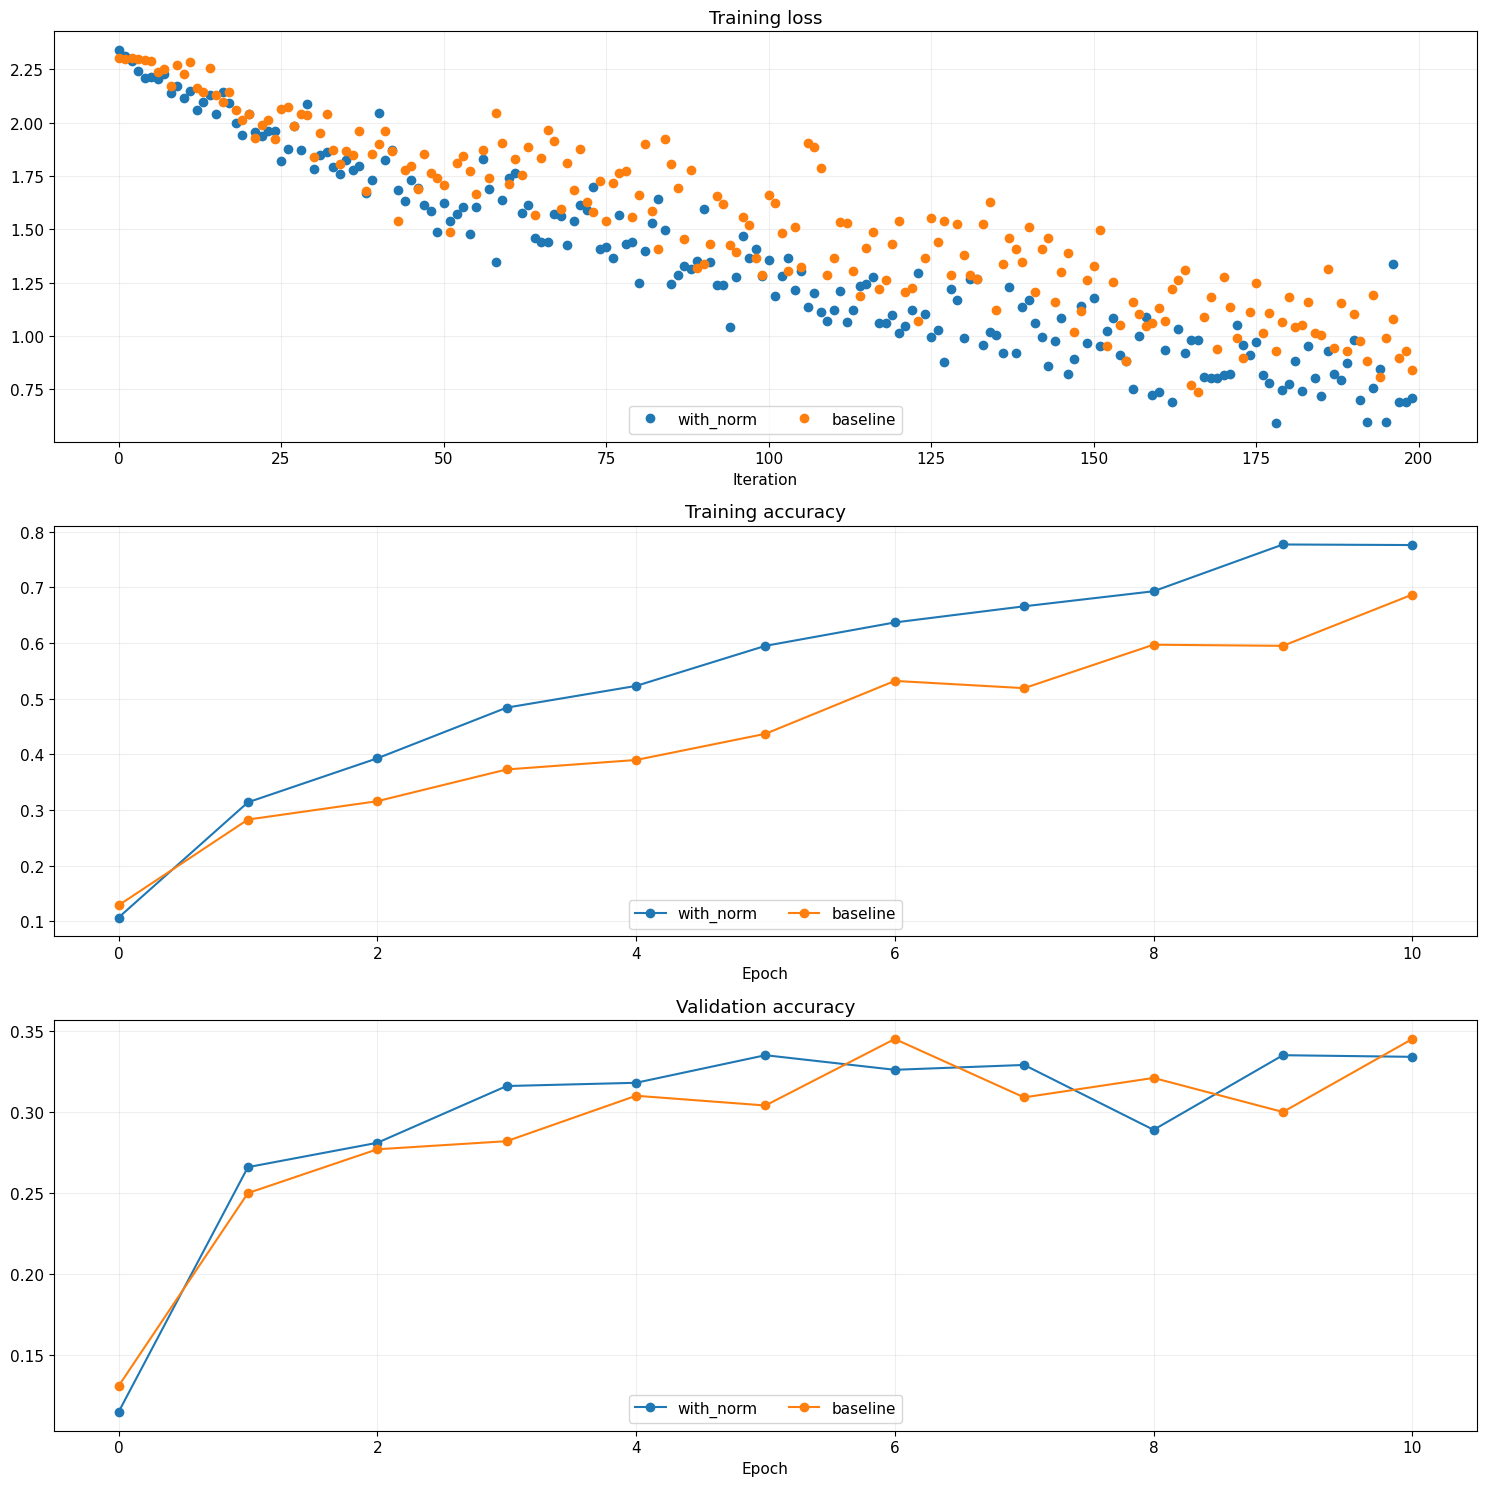

In [12]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    """utility function for plotting training history"""
    plt.title(title)
    plt.xlabel(label)
    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)
    for i in range(num_bn):
        label='with_norm'
        if labels is not None:
            label += str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=label)
    label='baseline'
    if labels is not None:
        label += str(labels[0])
    plt.plot(bl_plot, bl_marker, label=label)
    plt.legend(loc='lower center', ncol=num_bn+1) 

    
plt.subplot(3, 1, 1)
plot_training_history('Training loss','Iteration', solver, [bn_solver], \
                      lambda x: x.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Training accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Validation accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.val_acc_history, bl_marker='-o', bn_marker='-o')

plt.gcf().set_size_inches(15, 15)
plt.tight_layout()
plt.show()

# Batch Normalization and Initialization
We will now run a small experiment to study the interaction of batch normalization and weight initialization.

The first cell will train 8-layer networks both with and without batch normalization using different scales for weight initialization. The second layer will plot training accuracy, validation set accuracy, and training loss as a function of the weight initialization scale.

In [13]:
np.random.seed(231)
# Try training a very deep net with batchnorm
hidden_dims = [50, 50, 50, 50, 50, 50, 50]
num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

bn_solvers_ws = {}
solvers_ws = {}
weight_scales = np.logspace(-4, 0, num=20)
for i, weight_scale in enumerate(weight_scales):
  print('Running weight scale %d / %d' % (i + 1, len(weight_scales)))
  bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
  model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

  bn_solver = Solver(bn_model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
  bn_solver.train()
  bn_solvers_ws[weight_scale] = bn_solver

  solver = Solver(model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
  solver.train()
  solvers_ws[weight_scale] = solver

print('Initialization sweep: scale, baseline train/val/loss, batchnorm train/val/loss')
for ws in weight_scales:
    baseline, normalized = solvers_ws[ws], bn_solvers_ws[ws]
    print('%.6g: %.3f / %.3f / %.6g; %.3f / %.3f / %.6g' %
          (ws, max(baseline.train_acc_history), baseline.best_val_acc,
           np.mean(baseline.loss_history[-100:]),
           max(normalized.train_acc_history), normalized.best_val_acc,
           np.mean(normalized.loss_history[-100:])))

Running weight scale 1 / 20


Running weight scale 2 / 20


Running weight scale 3 / 20


Running weight scale 4 / 20


Running weight scale 5 / 20


...

Running weight scale 17 / 20


Running weight scale 18 / 20


Running weight scale 19 / 20


Running weight scale 20 / 20


Initialization sweep: scale, baseline train/val/loss, batchnorm train/val/loss
0.0001: 0.112 / 0.119 / 2.3012; 0.311 / 0.239 / 1.81149
0.000162378: 0.112 / 0.119 / 2.30085; 0.328 / 0.264 / 1.79728
0.000263665: 0.112 / 0.119 / 2.30045; 0.330 / 0.232 / 1.78248
0.000428133: 0.112 / 0.119 / 2.30144; 0.333 / 0.249 / 1.76428
0.000695193: 0.112 / 0.119 / 2.30071; 0.323 / 0.237 / 1.79852
0.00112884: 0.181 / 0.164 / 2.13251; 0.309 / 0.234 / 1.76601
0.00183298: 0.112 / 0.119 / 2.30192; 0.391 / 0.275 / 1.77231
0.00297635: 0.112 / 0.119 / 2.30225; 0.379 / 0.285 / 1.70663
0.00483293: 0.205 / 0.196 / 1.94987; 0.416 / 0.268 / 1.67285
0.0078476: 0.217 / 0.198 / 1.9683; 0.460 / 0.290 / 1.67352
0.0127427: 0.281 / 0.203 / 1.95358; 0.510 / 0.294 / 1.59255
0.0206914: 0.327 / 0.252 / 1.79578; 0.540 / 0.324 / 1.54632
0.0335982: 0.345 / 0.274 / 1.74711; 0.562 / 0.312 / 1.49313
0.0545559: 0.566 / 0.312 / 1.41782; 0.638 / 0.309 / 1.38144
0.0885867: 0.735 / 0.295 / 1.06423; 0.603 / 0.276 / 1.52118
0.143845: 0.64

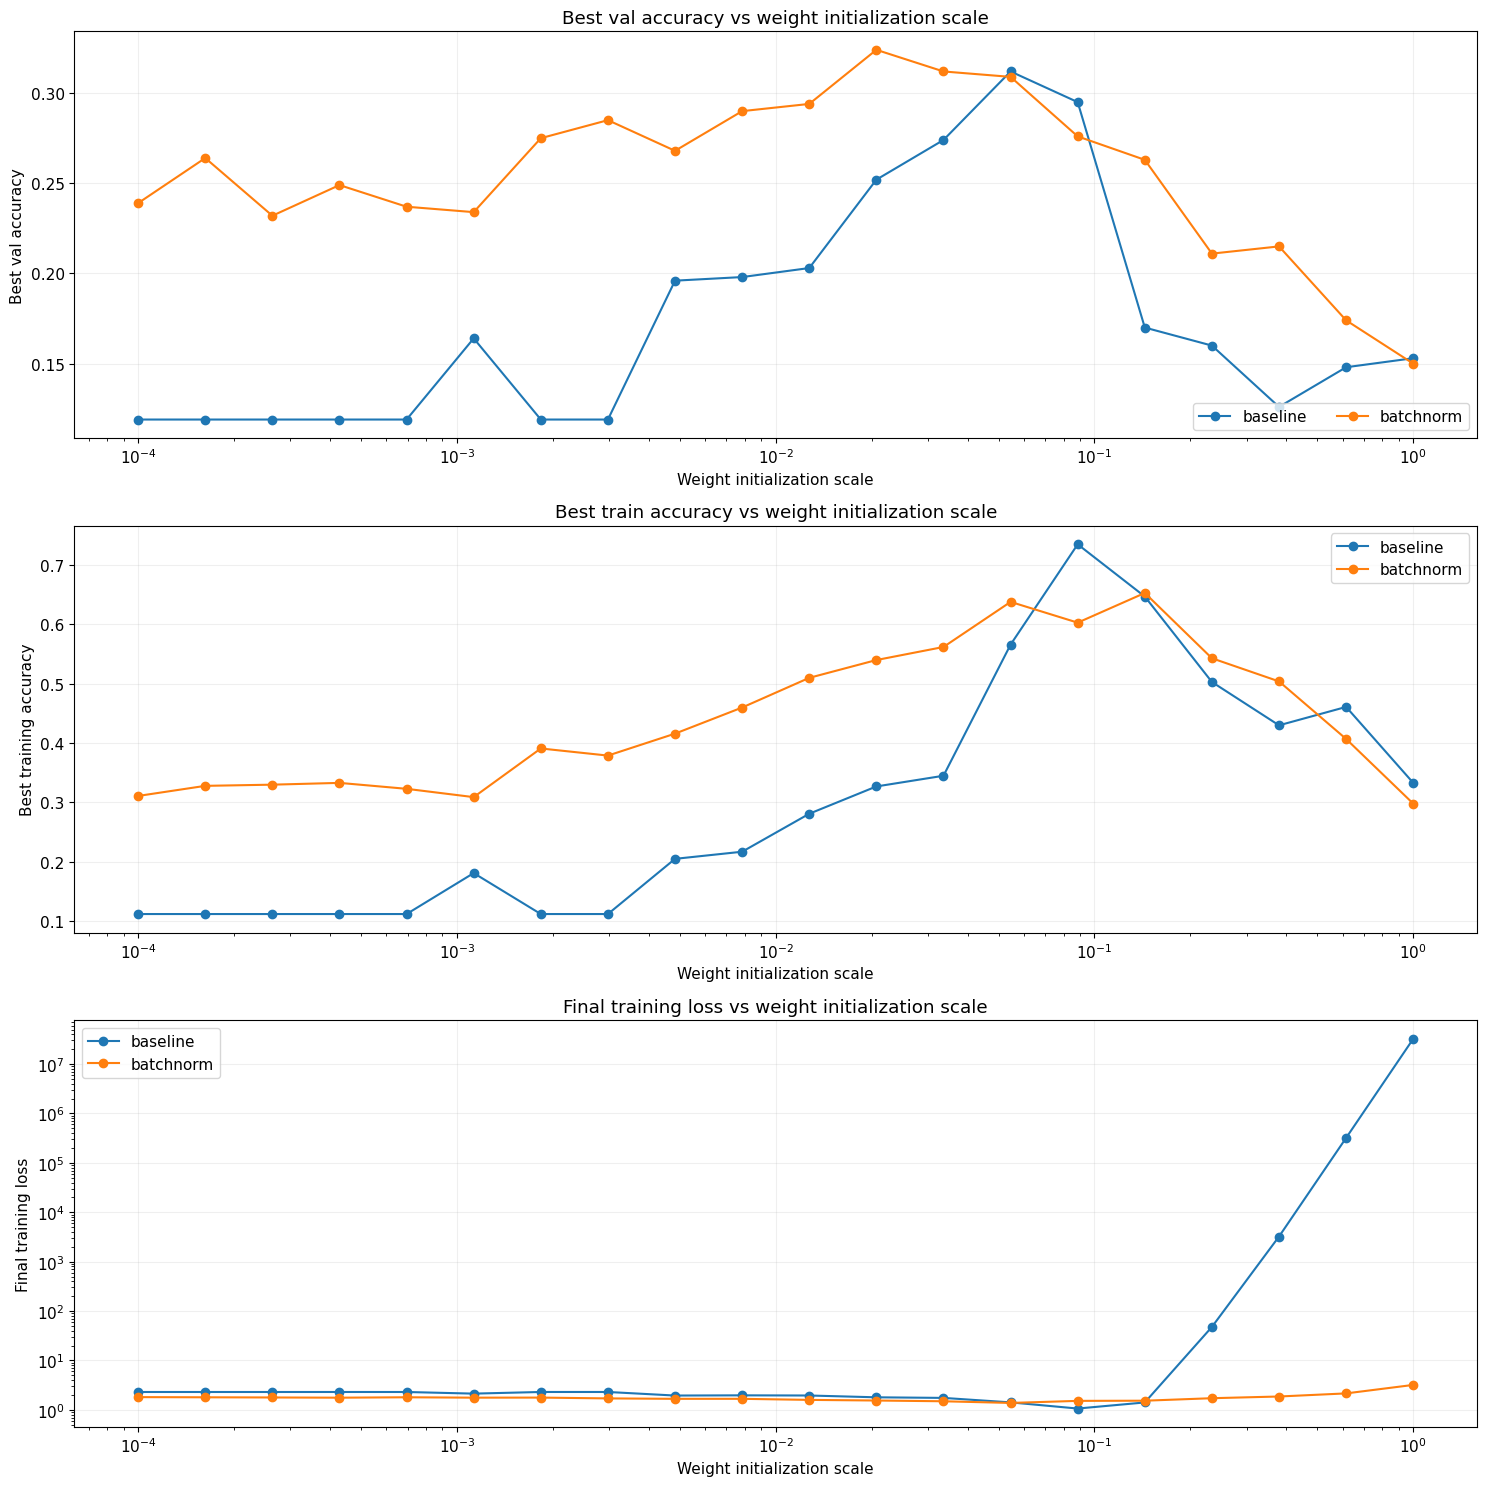

In [14]:
# Plot results of weight scale experiment
best_train_accs, bn_best_train_accs = [], []
best_val_accs, bn_best_val_accs = [], []
final_train_loss, bn_final_train_loss = [], []

for ws in weight_scales:
  best_train_accs.append(max(solvers_ws[ws].train_acc_history))
  bn_best_train_accs.append(max(bn_solvers_ws[ws].train_acc_history))
  
  best_val_accs.append(max(solvers_ws[ws].val_acc_history))
  bn_best_val_accs.append(max(bn_solvers_ws[ws].val_acc_history))
  
  final_train_loss.append(np.mean(solvers_ws[ws].loss_history[-100:]))
  bn_final_train_loss.append(np.mean(bn_solvers_ws[ws].loss_history[-100:]))
  
plt.subplot(3, 1, 1)
plt.title('Best val accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best val accuracy')
plt.semilogx(weight_scales, best_val_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_val_accs, '-o', label='batchnorm')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)
plt.title('Best train accuracy vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best training accuracy')
plt.semilogx(weight_scales, best_train_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_train_accs, '-o', label='batchnorm')
plt.legend()

plt.subplot(3, 1, 3)
plt.title('Final training loss vs weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Final training loss')
plt.semilogx(weight_scales, final_train_loss, '-o', label='baseline')
plt.semilogx(weight_scales, bn_final_train_loss, '-o', label='batchnorm')
plt.legend()
plt.yscale('log')  # Show both small losses and unstable large-scale losses.

plt.gcf().set_size_inches(15, 15)
plt.tight_layout()
plt.show()

## Inline Question 1:
Describe the results of this experiment. How does the scale of weight initialization affect models with/without batch normalization differently, and why?

## Answer:

The unnormalized network is much more sensitive to initialization scale. At weight_scale=1e-4 it stays near chance (11.2% best training accuracy, 11.9% best validation accuracy, mean final loss 2.30), while BatchNorm reaches 31.1% training and 23.9% validation accuracy. At scale 1, the baseline's mean final loss grows to about 3.24e7, versus 3.20 with BatchNorm. The baseline works best in a narrower intermediate range; its best validation accuracy is 31.2% near scale 0.0546, while the best BatchNorm validation accuracy is 32.4% near scale 0.0207.

Small weights can make signals and gradients shrink through many layers, while large weights can amplify activations and produce very large losses. Normalizing hidden activations makes a wider range of scales usable. It does not make the network completely scale-independent: epsilon matters at very small variances, the final affine layer is not normalized, and the optimizer's relative step size still changes with weight magnitude.

# Batch normalization and batch size
We will now run a small experiment to study the interaction of batch normalization and batch size.

The first cell will train 6-layer networks both with and without batch normalization using different batch sizes. The second layer will plot training accuracy and validation set accuracy over time.

In [15]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)
    # Try training a very deep net with batchnorm
    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs=10
    weight_scale = 2e-2
    batch_sizes = [5,10,50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('No normalization: batch size = ',solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()
    print('  baseline: best train=%.3f, final train=%.3f, best val=%.3f' %
          (max(solver.train_acc_history), solver.train_acc_history[-1], solver.best_val_acc))
    
    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size=batch_sizes[i]
        print('Normalization: batch size = ',b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        print('  %s, batch %d: best train=%.3f, final train=%.3f, best val=%.3f' %
              (normalization_mode, b_size, max(bn_solver.train_acc_history),
               bn_solver.train_acc_history[-1], bn_solver.best_val_acc))
        bn_solvers.append(bn_solver)
        
    return bn_solvers, solver, batch_sizes

batch_sizes = [5,10,50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

No normalization: batch size =  5


  baseline: best train=0.627, final train=0.627, best val=0.334
Normalization: batch size =  5


  batchnorm, batch 5: best train=0.442, final train=0.442, best val=0.331
Normalization: batch size =  10


  batchnorm, batch 10: best train=0.669, final train=0.669, best val=0.328
Normalization: batch size =  50


  batchnorm, batch 50: best train=0.859, final train=0.859, best val=0.368


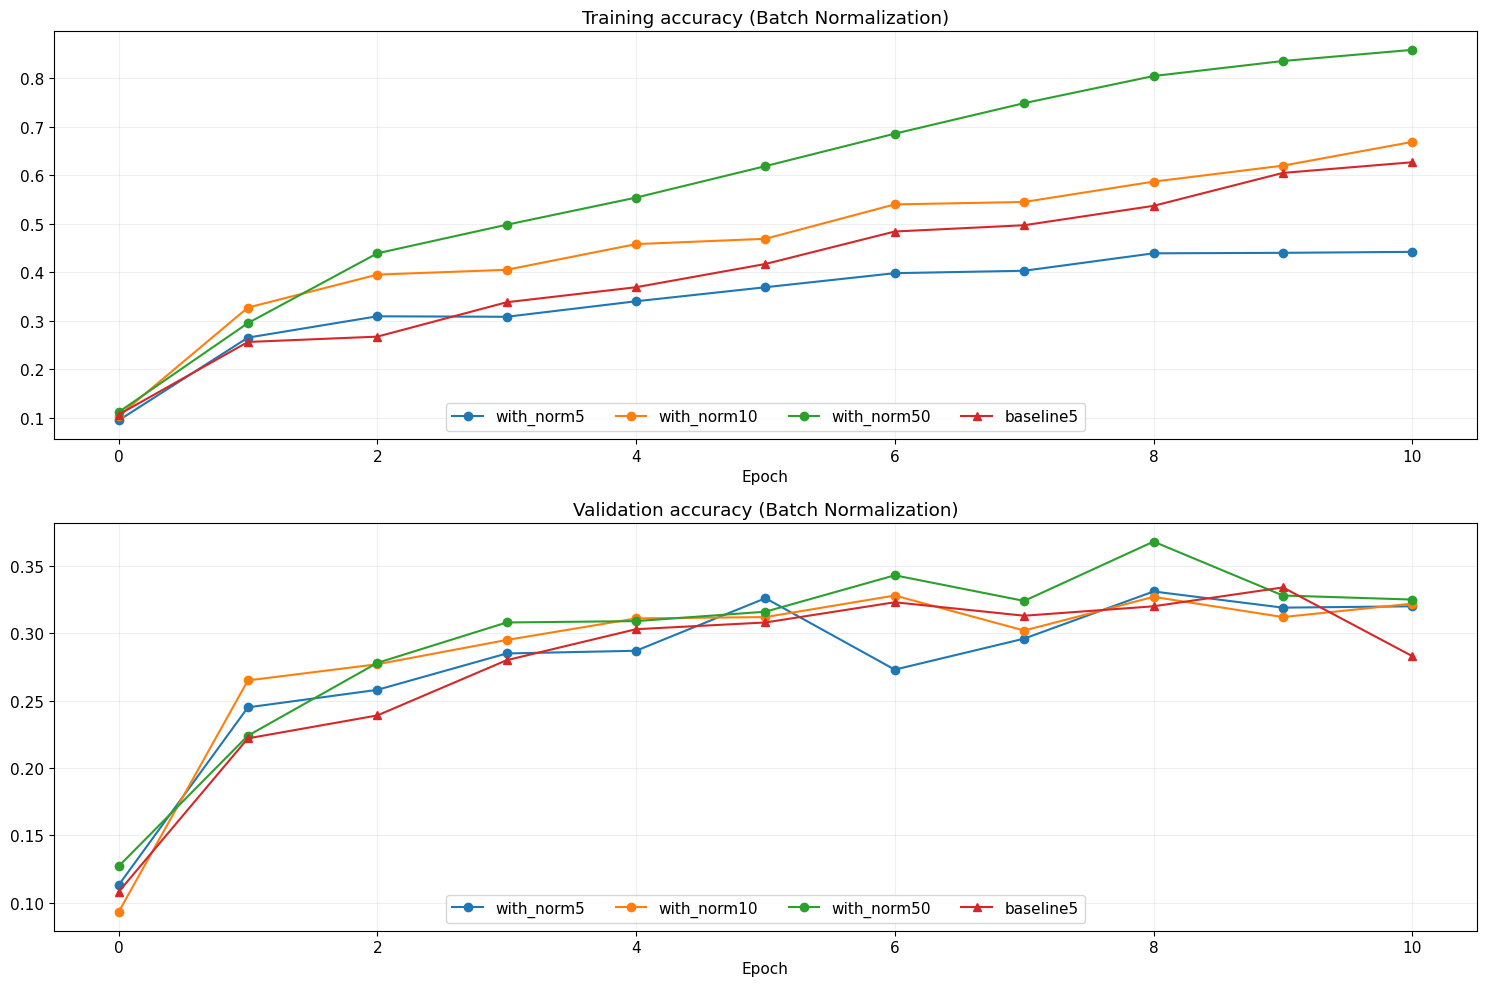

In [16]:
plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.tight_layout()
plt.show()

## Inline Question 2:
Describe the results of this experiment. What does this imply about the relationship between batch normalization and batch size? Why is this relationship observed?

## Answer:

With BatchNorm, batch sizes 5, 10, and 50 reach best training accuracies of 44.2%, 66.9%, and 85.9%, respectively. Their best validation accuracies are 33.1%, 32.8%, and 36.8%, so validation does not improve monotonically, but the largest batch performs best in this run. The unnormalized batch-5 baseline reaches 62.7% training and 33.4% validation accuracy.

BatchNorm estimates each feature's mean and variance from the current minibatch. Very small batches give noisier estimates and a larger mismatch with the running statistics used at test time; larger batches generally stabilize those estimates. The comparison also changes gradient noise and the number of updates per epoch, so it is not a pure isolation of normalization effects.

# Layer Normalization
Batch normalization has proved to be effective in making networks easier to train, but the dependency on batch size makes it less useful in complex networks which have a cap on the input batch size due to hardware limitations. 

Several alternatives to batch normalization have been proposed to mitigate this problem; one such technique is Layer Normalization [2]. Instead of normalizing over the batch, we normalize over the features. In other words, when using Layer Normalization, each feature vector corresponding to a single datapoint is normalized based on the sum of all terms within that feature vector.

[2] [Ba, Jimmy Lei, Jamie Ryan Kiros, and Geoffrey E. Hinton. "Layer Normalization." stat 1050 (2016): 21.](https://arxiv.org/pdf/1607.06450.pdf)

## Inline Question 3:
Which of these data preprocessing steps is analogous to batch normalization, and which is analogous to layer normalization?

1. Scaling each image in the dataset, so that the RGB channels for each row of pixels within an image sums up to 1.
2. Scaling each image in the dataset, so that the RGB channels for all pixels within an image sums up to 1.  
3. Subtracting the mean image of the dataset from each image in the dataset.
4. Setting all RGB values to either 0 or 1 depending on a given threshold.

## Answer:

1 and 2 are analogous to layer normalization because they calculate a scale using only features within one image: 1 normalizes each row separately, while 2 normalizes the whole image. Option 1 can be viewed as applying layer normalization to each row's feature vector; option 2 applies the same within-example idea to the full image feature vector.

3 is analogous to batch normalization because the mean image is a statistic shared across examples, with a separate mean for each image feature. 4 is thresholding and is analogous to neither method.

These are analogies about which values share normalization statistics. Scaling values to sum to one is not the same formula as subtracting a mean and dividing by a standard deviation; row-wise and whole-image normalization also use different feature axes.

# Layer Normalization: Implementation

Now you'll implement layer normalization. This step should be relatively straightforward, as conceptually the implementation is almost identical to that of batch normalization. One significant difference though is that for layer normalization, we do not keep track of the moving moments, and the testing phase is identical to the training phase, where the mean and variance are directly calculated per datapoint.

Here's what you need to do:

* In `cs682/layers.py`, implement the forward pass for layer normalization in the function `layernorm_backward`. 

Run the cell below to check your results.
* In `cs682/layers.py`, implement the backward pass for layer normalization in the function `layernorm_backward`. 

Run the second cell below to check your results.
* Modify `cs682/classifiers/fc_net.py` to add layer normalization to the `FullyConnectedNet`. When the `normalization` flag is set to `"layernorm"` in the constructor, you should insert a layer normalization layer before each ReLU nonlinearity. 

Run the third cell below to run the batch size experiment on layer normalization.

In [17]:
# Check the training-time forward pass by checking means and variances
# of features both before and after layer normalization   

# Simulate the forward pass for a two-layer network
np.random.seed(231)
N, D1, D2, D3 =4, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before layer normalization:')
print_mean_std(a,axis=1)

gamma = np.ones(D3)
beta = np.zeros(D3)
# Means should be close to zero and stds close to one
print('After layer normalization (gamma=1, beta=0)')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

gamma = np.asarray([3.0,3.0,3.0])
beta = np.asarray([5.0,5.0,5.0])
# Now means should be close to beta and stds close to gamma
print('After layer normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

Before layer normalization:
  means:  [-59.06673243 -47.60782686 -43.31137368 -26.40991744]
  stds:   [10.07429373 28.39478981 35.28360729  4.01831507]

After layer normalization (gamma=1, beta=0)
  means:  [-4.81096644e-16 -7.40148683e-17 -1.48029737e-16 -2.96059473e-16]
  stds:   [0.99999995 0.99999999 1.         0.99999969]

After layer normalization (gamma= [3. 3. 3.] , beta= [5. 5. 5.] )
  means:  [5. 5. 5. 5.]
  stds:   [2.99999985 2.99999998 2.99999999 2.99999907]



In [18]:
# Gradient check layernorm backward pass
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

ln_param = {}
fx = lambda x: layernorm_forward(x, gamma, beta, ln_param)[0]
fg = lambda a: layernorm_forward(x, a, beta, ln_param)[0]
fb = lambda b: layernorm_forward(x, gamma, b, ln_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = layernorm_forward(x, gamma, beta, ln_param)
dx, dgamma, dbeta = layernorm_backward(dout, cache)

#You should expect to see relative errors between 1e-12 and 1e-8
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

# Check layer normalization inside a full network, including regularization.
np.random.seed(231)
X_check = np.random.randn(2, 15)
y_check = np.random.randint(10, size=2)
for reg in [0.0, 3.14]:
    print('Layernorm network gradient check, reg =', reg)
    model = FullyConnectedNet([20, 30], input_dim=15, num_classes=10,
                              weight_scale=5e-2, dtype=np.float64,
                              normalization='layernorm', reg=reg)
    loss, grads = model.loss(X_check, y_check)
    for name in sorted(grads):
        numerical = eval_numerical_gradient(
            lambda _: model.loss(X_check, y_check)[0], model.params[name], verbose=False)
        error = rel_error(numerical, grads[name])
        print('%s relative error: %.2e' % (name, error))
        np.testing.assert_allclose(numerical, grads[name], rtol=1e-4, atol=1e-8)


dx error:  1.51153770738727e-09
dgamma error:  2.9640168238315895e-12
dbeta error:  2.276445013433725e-12
Layernorm network gradient check, reg = 0.0


W1 relative error: 6.30e-09
W2 relative error: 4.04e-08


W3 relative error: 2.35e-08


b1 relative error: 2.92e-09
b2 relative error: 1.13e-09
b3 relative error: 7.30e-11
beta1 relative error: 3.32e-09
beta2 relative error: 2.37e-09
gamma1 relative error: 3.44e-06
gamma2 relative error: 1.23e-08
Layernorm network gradient check, reg = 3.14


W1 relative error: 2.78e-08
W2 relative error: 4.59e-08


W3 relative error: 2.54e-08


b1 relative error: 5.70e-10
b2 relative error: 2.85e-08
b3 relative error: 2.04e-10
beta1 relative error: 1.36e-09
beta2 relative error: 1.34e-09
gamma1 relative error: 1.51e-08
gamma2 relative error: 7.97e-09


# Layer Normalization and batch size

We will now run the previous batch size experiment with layer normalization instead of batch normalization. Compared to the previous experiment, you should see a markedly smaller influence of batch size on the training history!

In this seeded experiment, LayerNorm's best validation accuracies at batch sizes 5, 10, and 50 are 35.0%, 35.3%, and 35.1%. This is a much smaller spread than BatchNorm's 33.1%, 32.8%, and 36.8%. LayerNorm calculates statistics within each example, so changing the number of other examples does not change its normalization statistics; optimization effects of batch size still remain.

No normalization: batch size =  5


  baseline: best train=0.627, final train=0.627, best val=0.334
Normalization: batch size =  5


  layernorm, batch 5: best train=0.739, final train=0.739, best val=0.350
Normalization: batch size =  10


  layernorm, batch 10: best train=0.810, final train=0.810, best val=0.353
Normalization: batch size =  50


  layernorm, batch 50: best train=0.790, final train=0.779, best val=0.351


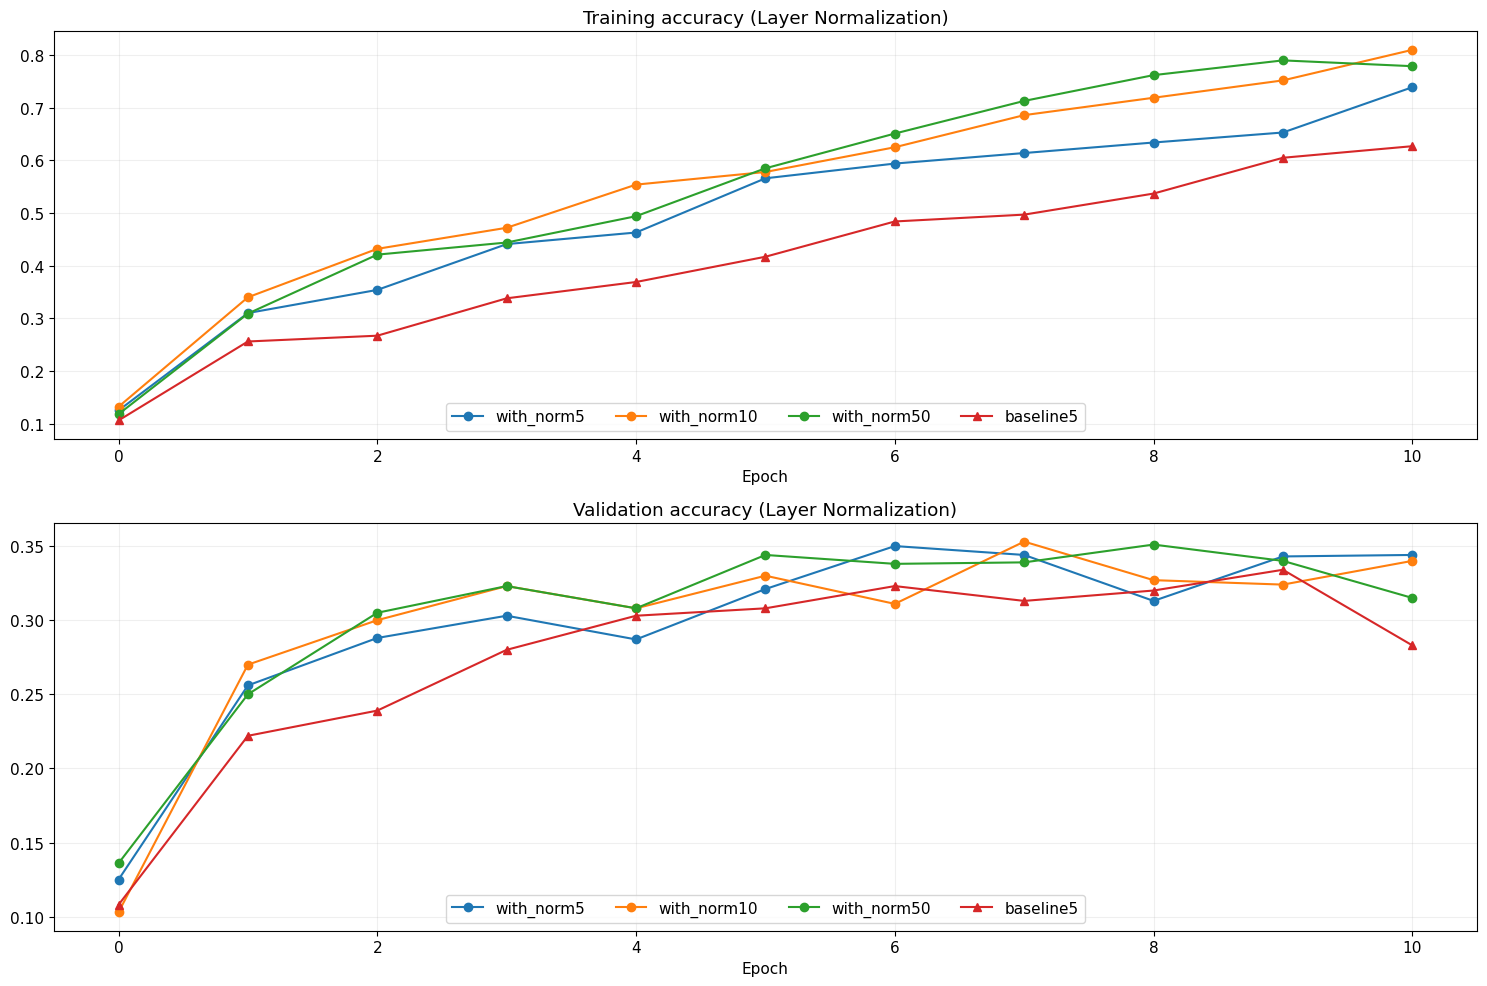

In [19]:
ln_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('layernorm')

plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Layer Normalization)','Epoch', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Layer Normalization)','Epoch', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.tight_layout()
plt.show()

## Inline Question 4:
When is layer normalization likely to not work well, and why?

1. Using it in a very deep network
2. Having a very small dimension of features
3. Having a high regularization term


## Answer:

2: a very small feature dimension. Layer normalization estimates each example's mean and variance from its features, so with very few features it can remove much of the useful signal. In the extreme case of one feature, the centered input is always zero and the normalized output reduces to beta. Network depth alone is not a reason for layer normalization to fail; a large regularization coefficient can cause underfitting with any of these architectures.